# Student Performance Prediction System
**Internship Mini Project – AI / Machine Learning**  
**Student:** Twinkle Ghangare | **Mentor:** Sri Nivasan Pillai

Workflow: Data → Cleaning → Analysis → Feature Selection → Training → Testing → Evaluation → Prediction

**Goal:** Predict a student's final grade (G3, scale 0–20) from demographic, social and school-related information.

**Dataset:** UCI *Student Performance* dataset (mathematics course, 395 students). Source: https://archive.ics.uci.edu/dataset/320/student+performance

## 1. Setup – import libraries and create folders

In [1]:
import os, shutil, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

for folder in ["data", "images", "results"]:
    os.makedirs(folder, exist_ok=True)

RANDOM_STATE = 42   # fixed so results are reproducible

## 2. Get the dataset
This cell downloads the dataset from UCI and saves `data/student-mat.csv`. If the download fails (no internet), download the ZIP manually from the UCI link above, extract it and put `student-mat.csv` inside the `data/` folder.

In [2]:
DATA_PATH = "data/student-mat.csv"

if not os.path.exists(DATA_PATH):
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    zip_path = "data/student_performance.zip"
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("data/raw")
    # the archive may contain a nested zip, so extract that too
    for root, _, files in os.walk("data/raw"):
        for f in files:
            if f.endswith(".zip"):
                with zipfile.ZipFile(os.path.join(root, f)) as z:
                    z.extractall("data/raw")
    for root, _, files in os.walk("data/raw"):
        if "student-mat.csv" in files:
            shutil.copy(os.path.join(root, "student-mat.csv"), DATA_PATH)
            break

print("Dataset ready:", os.path.exists(DATA_PATH))

Dataset ready: True


## 3. Understand the dataset

In [3]:
df = pd.read_csv(DATA_PATH, sep=";")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [5]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


**Important columns**

| Column | Meaning |
|---|---|
| `studytime` | Weekly study time (1 = <2h … 4 = >10h) |
| `failures` | Number of past class failures |
| `absences` | Number of school absences |
| `Medu`, `Fedu` | Mother's / father's education (0–4) |
| `goout`, `Dalc`, `Walc` | Going out, workday and weekend alcohol use (1–5) |
| `higher` | Wants to take higher education (yes/no) |
| `G1`, `G2` | First and second period grades (0–20) |
| **`G3`** | **Final grade (0–20) – our target** |

## 4. Data cleaning and missing values

In [6]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Cleaning steps (safe even if nothing is missing):
df = df.drop_duplicates()
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())          # numeric -> median
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])                          # text -> most common value

print("Missing after cleaning:", df.isnull().sum().sum())
print("Students with final grade 0:", (df['G3'] == 0).sum(), "(kept - they are real students who dropped out / did not take the exam)")

Total missing values: 0
Duplicate rows: 0
Missing after cleaning: 0
Students with final grade 0: 38 (kept - they are real students who dropped out / did not take the exam)


## 5. Exploratory Data Analysis (EDA)

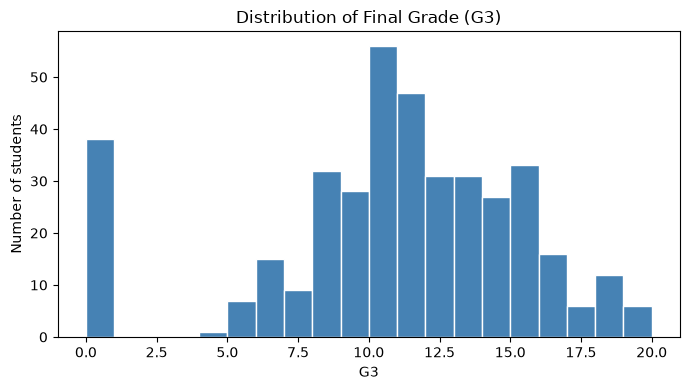

In [7]:
plt.figure(figsize=(7, 4))
plt.hist(df["G3"], bins=20, color="steelblue", edgecolor="white")
plt.title("Distribution of Final Grade (G3)")
plt.xlabel("G3"); plt.ylabel("Number of students")
plt.tight_layout(); plt.savefig("images/01_g3_distribution.png", dpi=150); plt.show()

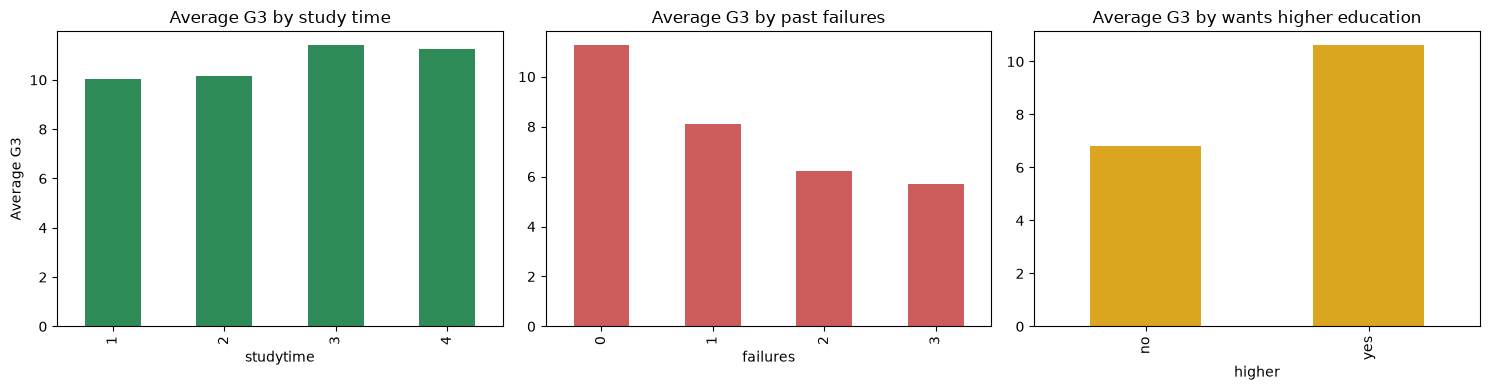

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("studytime")["G3"].mean().plot(kind="bar", ax=axes[0], color="seagreen")
axes[0].set_title("Average G3 by study time"); axes[0].set_ylabel("Average G3")
df.groupby("failures")["G3"].mean().plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("Average G3 by past failures")
df.groupby("higher")["G3"].mean().plot(kind="bar", ax=axes[2], color="goldenrod")
axes[2].set_title("Average G3 by wants higher education")
plt.tight_layout(); plt.savefig("images/02_g3_by_factors.png", dpi=150); plt.show()

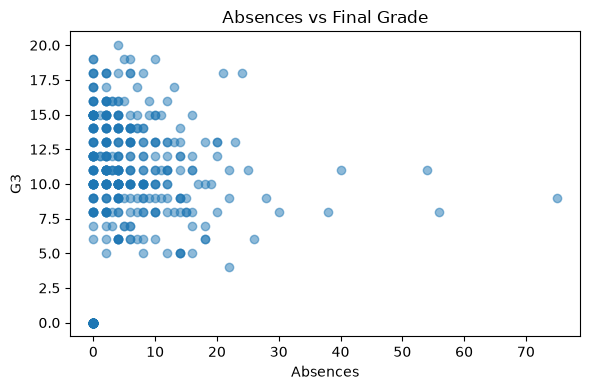

In [9]:
plt.figure(figsize=(6, 4))
plt.scatter(df["absences"], df["G3"], alpha=0.5)
plt.title("Absences vs Final Grade"); plt.xlabel("Absences"); plt.ylabel("G3")
plt.tight_layout(); plt.savefig("images/03_absences_vs_g3.png", dpi=150); plt.show()

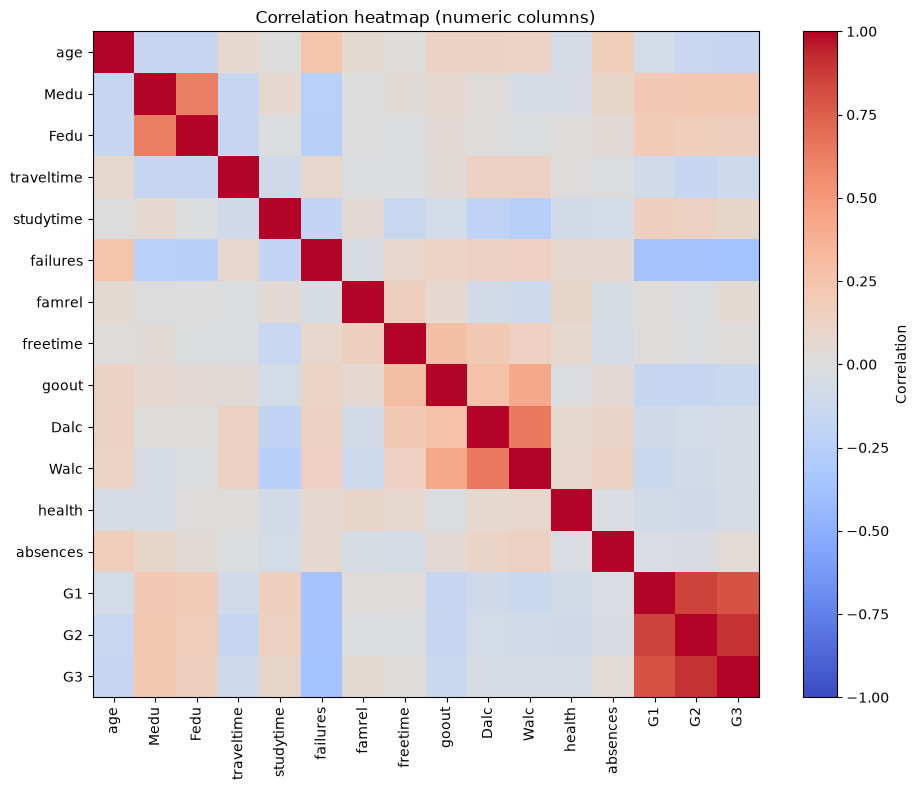

Correlation of each numeric column with G3:
G2            0.90
G1            0.80
Medu          0.22
Fedu          0.15
studytime     0.10
famrel        0.05
absences      0.03
freetime      0.01
Walc         -0.05
Dalc         -0.05
health       -0.06
traveltime   -0.12
goout        -0.13
age          -0.16
failures     -0.36
Name: G3, dtype: float64


In [10]:
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation heatmap (numeric columns)")
plt.tight_layout(); plt.savefig("images/04_correlation_heatmap.png", dpi=150); plt.show()

print("Correlation of each numeric column with G3:")
print(corr["G3"].drop("G3").sort_values(ascending=False).round(2))

**Patterns to note (check against your own charts and write them in the report):**
- `G1` and `G2` are very strongly correlated with `G3` – students who did well earlier keep doing well.
- `failures` is negatively correlated with `G3`.
- Parents' education (`Medu`, `Fedu`) and `studytime` show a weaker positive relation.

## 6. Feature selection

`G1` and `G2` are so strongly linked with `G3` that they can dominate the model. To keep the project meaningful, I compare **two scenarios**:

- **Scenario A – with G1 & G2:** most accurate, but only usable *after* two exams are done.
- **Scenario B – without G1 & G2:** uses only background/behaviour features, so it can flag at-risk students *early*.

In [11]:
target = "G3"
X_raw_A = df.drop(columns=[target])                      # all features
X_raw_B = df.drop(columns=[target, "G1", "G2"])          # no earlier grades
y = df[target]

# Convert text columns (yes/no, school names ...) to numbers with one-hot encoding
X_A = pd.get_dummies(X_raw_A, drop_first=True)
X_B = pd.get_dummies(X_raw_B, drop_first=True)
print("Features in A:", X_A.shape[1], "| Features in B:", X_B.shape[1])

Features in A: 41 | Features in B: 39


## 7. Train / test split
80% of students for training, 20% for testing. The model never sees the test students while learning.

In [12]:
XA_train, XA_test, y_train, y_test = train_test_split(X_A, y, test_size=0.2, random_state=RANDOM_STATE)
XB_train, XB_test, _, _ = train_test_split(X_B, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train size:", len(y_train), "| Test size:", len(y_test))

Train size: 316 | Test size: 79


## 8. Train and evaluate models
Two models: **Linear Regression** (simple baseline) and **Random Forest** (handles non-linear patterns).

Metrics:
- **MAE** – average error in grade points (lower is better)
- **RMSE** – like MAE but punishes big mistakes more (lower is better)
- **R²** – share of grade variation explained by the model (closer to 1 is better)

In [13]:
def evaluate(model, X_tr, X_te, name):
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    pred = np.clip(pred, 0, 20)                         # grades are between 0 and 20
    return {
        "Model": name,
        "MAE": round(mean_absolute_error(y_test, pred), 3),
        "RMSE": round(float(np.sqrt(mean_squared_error(y_test, pred))), 3),
        "R2": round(r2_score(y_test, pred), 3),
    }

results = [
    evaluate(LinearRegression(), XA_train, XA_test, "Linear Regression (A: with G1,G2)"),
    evaluate(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE), XA_train, XA_test, "Random Forest (A: with G1,G2)"),
    evaluate(LinearRegression(), XB_train, XB_test, "Linear Regression (B: without G1,G2)"),
    evaluate(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE), XB_train, XB_test, "Random Forest (B: without G1,G2)"),
]
results_df = pd.DataFrame(results)
results_df

,Model,MAE,RMSE,R2
0,"Linear Regression (A: with G1,G2)",1.598,2.351,0.730
1,"Random Forest (A: with G1,G2)",1.173,1.967,0.811
2,"Linear Regression (B: without G1,G2)",3.395,4.196,0.141
3,"Random Forest (B: without G1,G2)",3.082,3.869,0.270


## 9. Improve the model (hyperparameter tuning)
We tune the Random Forest for Scenario B with a small grid search.

In [14]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 3, 5],
}
grid = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE),
    param_grid, cv=5, scoring="neg_mean_absolute_error", n_jobs=-1
)
grid.fit(XB_train, y_train)
print("Best parameters:", grid.best_params_)

best_rf_B = grid.best_estimator_
pred_tuned = np.clip(best_rf_B.predict(XB_test), 0, 20)
tuned = {
    "Model": "Tuned Random Forest (B: without G1,G2)",
    "MAE": round(mean_absolute_error(y_test, pred_tuned), 3),
    "RMSE": round(float(np.sqrt(mean_squared_error(y_test, pred_tuned))), 3),
    "R2": round(r2_score(y_test, pred_tuned), 3),
}
results_df = pd.concat([results_df, pd.DataFrame([tuned])], ignore_index=True)
results_df.to_csv("results/model_results.csv", index=False)
results_df

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}


,Model,MAE,RMSE,R2
0,"Linear Regression (A: with G1,G2)",1.598,2.351,0.730
1,"Random Forest (A: with G1,G2)",1.173,1.967,0.811
2,"Linear Regression (B: without G1,G2)",3.395,4.196,0.141
3,"Random Forest (B: without G1,G2)",3.082,3.869,0.270
4,"Tuned Random Forest (B: without G1,G2)",3.148,3.935,0.245


## 10. Visualise model results

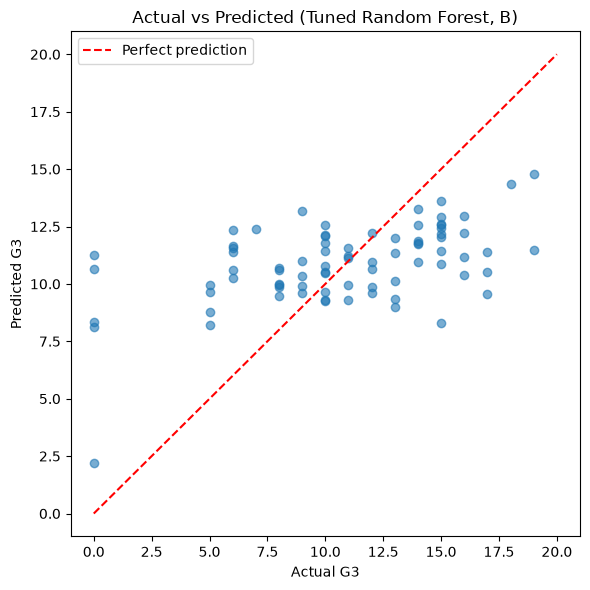

In [15]:
# Actual vs predicted for the tuned model (Scenario B)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_tuned, alpha=0.6)
plt.plot([0, 20], [0, 20], "r--", label="Perfect prediction")
plt.xlabel("Actual G3"); plt.ylabel("Predicted G3")
plt.title("Actual vs Predicted (Tuned Random Forest, B)")
plt.legend(); plt.tight_layout()
plt.savefig("images/05_actual_vs_predicted.png", dpi=150); plt.show()

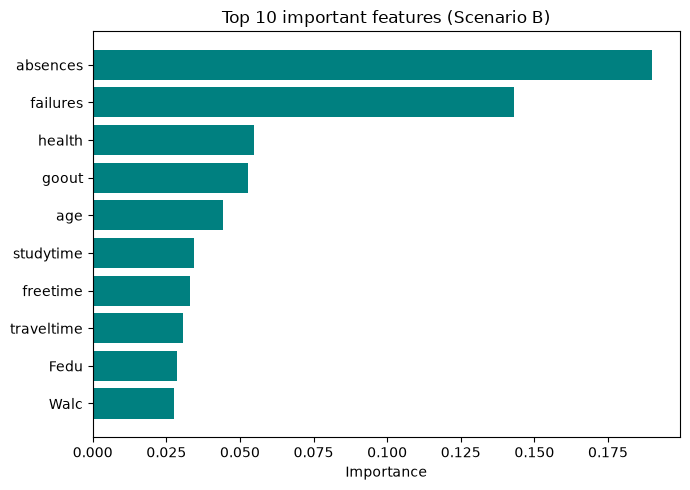

absences      0.190
failures      0.143
health        0.055
goout         0.053
age           0.044
studytime     0.034
freetime      0.033
traveltime    0.031
Fedu          0.028
Walc          0.028
dtype: float64


In [16]:
# Which features matter most?
importances = pd.Series(best_rf_B.feature_importances_, index=X_B.columns).sort_values(ascending=False)
top = importances.head(10)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, color="teal")
plt.title("Top 10 important features (Scenario B)")
plt.xlabel("Importance"); plt.tight_layout()
plt.savefig("images/06_feature_importance.png", dpi=150); plt.show()
print(importances.head(10).round(3))

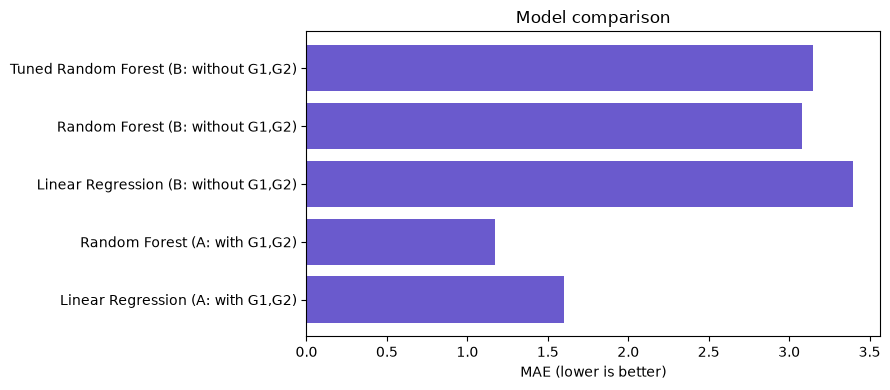

In [17]:
# Compare all models
plt.figure(figsize=(9, 4))
plt.barh(results_df["Model"], results_df["MAE"], color="slateblue")
plt.xlabel("MAE (lower is better)"); plt.title("Model comparison")
plt.tight_layout(); plt.savefig("images/07_model_comparison.png", dpi=150); plt.show()

## 11. Basic prediction system
Give the details of a student → get the predicted final grade. Anything you don't provide is filled with a typical value (median / most common) from the dataset. This uses the **tuned Random Forest from Scenario B**, so it needs no earlier grades.

In [18]:
typical = X_raw_B.iloc[0].copy()
for col in X_raw_B.columns:
    if pd.api.types.is_numeric_dtype(X_raw_B[col]):
        typical[col] = X_raw_B[col].median()
    else:
        typical[col] = X_raw_B[col].mode()[0]

def predict_student(**details):
    row = typical.copy()
    for key, value in details.items():
        if key not in row.index:
            raise ValueError(f"Unknown field: {key}")
        row[key] = value
    row_df = pd.get_dummies(pd.DataFrame([row]))
    row_df = row_df.reindex(columns=X_B.columns, fill_value=0)
    grade = float(np.clip(best_rf_B.predict(row_df)[0], 0, 20))
    return round(grade, 1)

def performance_level(grade):
    if grade >= 15: return "Good"
    if grade >= 10: return "Average"
    return "At risk"

for example in [
    dict(studytime=4, failures=0, absences=2, higher="yes", Medu=4, Fedu=4),
    dict(studytime=1, failures=2, absences=15, higher="no", Medu=1, Fedu=1, goout=5),
]:
    g = predict_student(**example)
    print(example, "->", g, "/ 20 ->", performance_level(g))

{'studytime': 4, 'failures': 0, 'absences': 2, 'higher': 'yes', 'Medu': 4, 'Fedu': 4} -> 10.7 / 20 -> Average
{'studytime': 1, 'failures': 2, 'absences': 15, 'higher': 'no', 'Medu': 1, 'Fedu': 1, 'goout': 5} -> 8.1 / 20 -> At risk


## 12. Conclusion
- Complete ML workflow implemented: data → cleaning → EDA → feature selection → training → testing → evaluation → prediction.
- Including `G1`/`G2` gives the best accuracy, while Scenario B still allows early identification of at-risk students.
- Final numbers are in `results/model_results.csv` and in the report.

**Limitations / future work:** small dataset (395 students), only the maths course used; could add the Portuguese dataset, try Gradient Boosting, and build a small web app (Streamlit).